In [8]:
import numpy as np
import pickle
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf
from statsmodels.tsa.filters.hp_filter import hpfilter
import warnings
from scipy.sparse import SparseEfficiencyWarning
warnings.simplefilter("ignore", SparseEfficiencyWarning)

from Functions import run_multistart, plot_predictive_density, compute_bimodality_series, plot_bimodality, plot_bimodality_and_series, run_psy
from MLE_Predictive_Density import neg_loglik_mar11_cauchy, neg_loglik_marx_cauchy, neg_loglik_student_mar, neg_loglik_student_marx, mar_cauchy_pred_density, marx_cauchy_pred_density, mar_studentt_pred_density, marx_studentt_pred_density


In [9]:
# Linear Trend of Volatility Scaling Function 

def linear_vol_scale(price, window=12):
    """
    Scale price using a linear trend on smoothed log-variance.
    """

    price = price.dropna()


    # -------------------------
    # Smooth variance 
    # -------------------------
    var_smooth = price.pow(2).ewm(span=window, adjust=False).mean()

    # -------------------------
    # Clean NaNs
    # -------------------------
    var_smooth = var_smooth.dropna()

    # -------------------------
    # Fit linear trend on LOG variance 
    # -------------------------
    log_var = np.log(var_smooth.values + 1e-8)

    t = np.arange(len(log_var))
    slope, intercept = np.polyfit(t, log_var, 1)

    log_var_trend = intercept + slope * t

    # Back to variance (guaranteed positive)
    var_trend = np.exp(log_var_trend)

    var_trend = pd.Series(var_trend, index=var_smooth.index)

    # -------------------------
    # Volatility (safe sqrt)
    # -------------------------
    vol = np.sqrt(var_trend)

    # safety floor (extra robustness)
    vol = vol.clip(lower=1e-8)

    return vol

### Import Nickel and detrend series with HP filter + linear trend of the volatility scaling

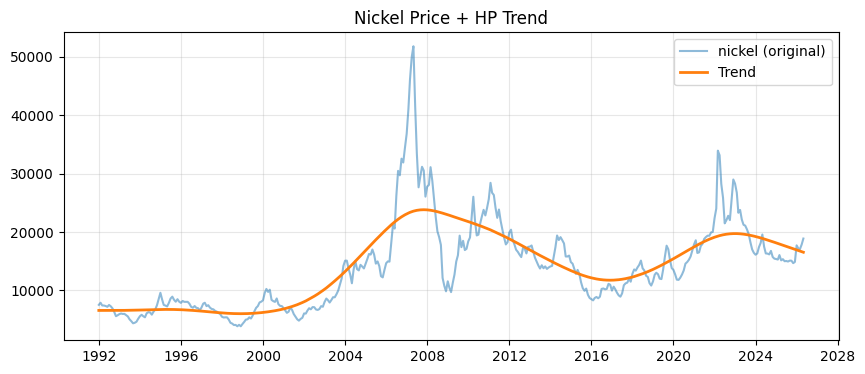

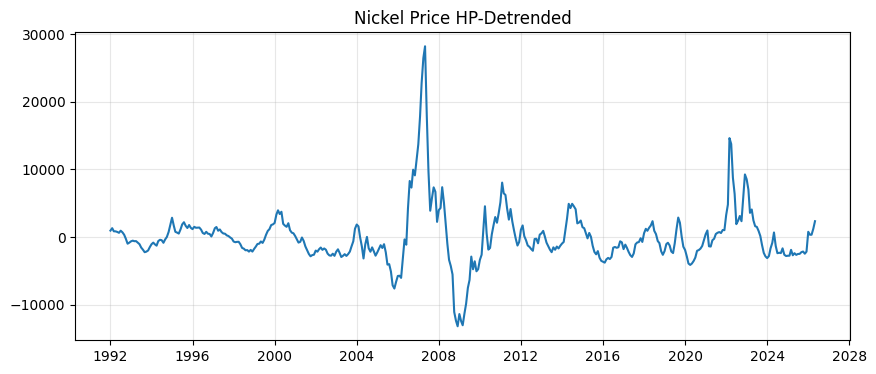

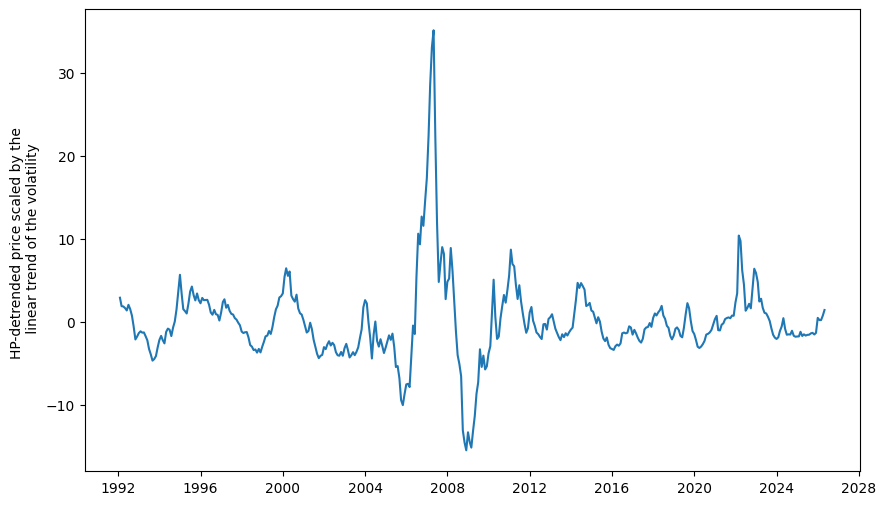

In [10]:
# -------------------------
# DATA
# -------------------------
df_nickel = pd.read_csv("PNICKUSDM.csv", parse_dates=["observation_date"])
df_nickel = df_nickel.dropna().set_index("observation_date")


# HP filter
cycle, trend = hpfilter(df_nickel["PNICKUSDM"], lamb=129600)

df_nickel["nickel_cycle"] = cycle
df_nickel["nickel_trend"] = trend


nickel_diff = (df_nickel["nickel_cycle"]).diff().dropna()
nickel_sigma = linear_vol_scale(nickel_diff)


df_nickel["nickel_scaled_cycle"]= df_nickel["nickel_cycle"]/nickel_sigma



# Plot trend decomposition
plt.figure(figsize=(10,4))
plt.plot(df_nickel.index, df_nickel["PNICKUSDM"], label="nickel (original)", alpha=0.5)
plt.plot(df_nickel.index, df_nickel["nickel_trend"], label="Trend", linewidth=2)
plt.title("Nickel Price + HP Trend")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Plot cycle 
plt.figure(figsize=(10,4))
plt.plot(df_nickel.index, df_nickel["nickel_cycle"])
plt.title("Nickel Price HP-Detrended")
plt.grid(True, alpha=0.3)
plt.show()

# Plot 
plt.figure(figsize=(10,6))
plt.plot(df_nickel.index, df_nickel["nickel_scaled_cycle"])
plt.ylabel("HP-detrended price scaled by the \n linear trend of the volatility")
# Increase tick-label font size (axis scales)
#plt.tick_params(axis="both", labelsize=14)
plt.show()



In [11]:
# Get PSY For Nickel and save as pickle

T = len(df_nickel)
r0 = 0.01 + 1.8 / np.sqrt(T)
swindow0 = int(np.floor(r0 * T))
yr = 2
Tb = 12 * yr + swindow0 - 1

psy = run_psy(
    y=df_nickel["PNICKUSDM"].values,
    dates=df_nickel.index,
    IC=2,
    adflag=6,
    Tb = Tb,
    nboot=1999)


with open("psy_nickel.pkl", "wb") as f:
    pickle.dump(psy, f)

### Extract Data for Exogeous Variables

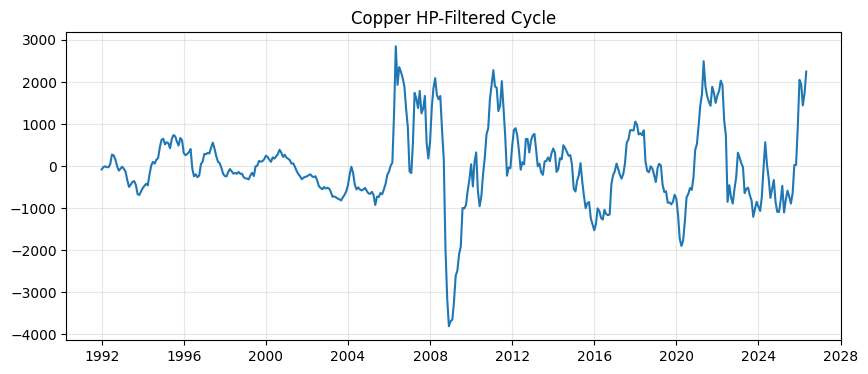

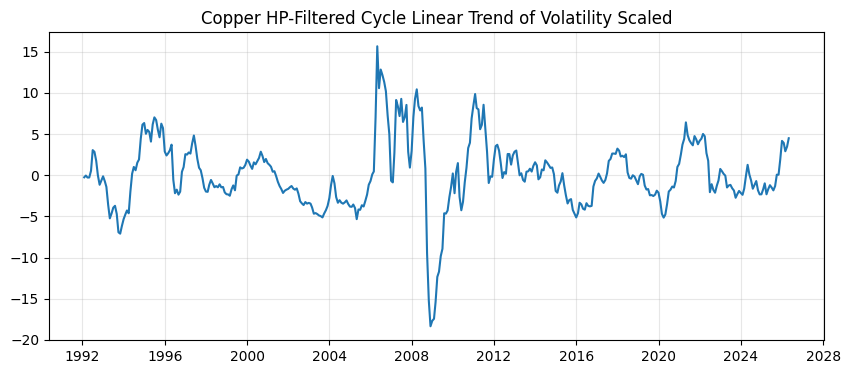

In [12]:
# -------------------------
# Copper
# -------------------------
df_copper = pd.read_csv("PCOPPUSDM.csv", parse_dates=["observation_date"])
df_copper = df_copper.dropna().set_index("observation_date")


# HP filter
copper_cycle, trend = hpfilter(df_copper, lamb=129600)

copper_diff = (copper_cycle).diff().dropna()
copper_sigma = linear_vol_scale(copper_diff)

copper= copper_cycle/copper_sigma


# Plot cyclical component
plt.figure(figsize=(10,4))
plt.plot(copper_cycle)
plt.title("Copper HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

# Plot cyclical component
plt.figure(figsize=(10,4))
plt.plot(copper)
plt.title("Copper HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

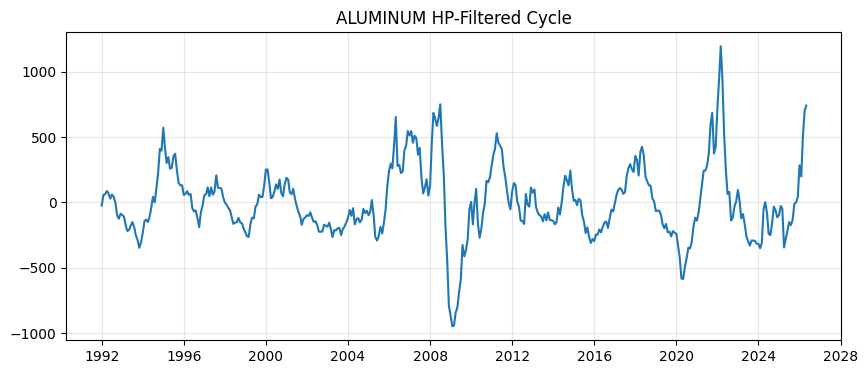

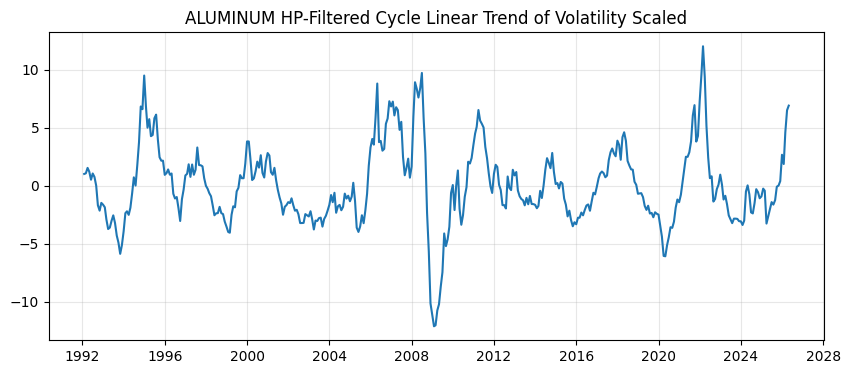

In [13]:
# -------------------------
# ALUMINUM
# -------------------------
df_al = pd.read_csv("PALUMUSDM.csv", parse_dates=["observation_date"])
df_al = df_al.dropna().set_index("observation_date")


# HP filter
al_cycle , trend = hpfilter(df_al["PALUMUSDM"], lamb=129600)

al_diff = (al_cycle).diff().dropna()
al_sigma = linear_vol_scale(al_diff)

al= al_cycle/al_sigma


# Plot cyclical component
plt.figure(figsize=(10,4))
plt.plot(al_cycle)
plt.title("ALUMINUM HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

# Plot cyclical component
plt.figure(figsize=(10,4))
plt.plot(al)
plt.title("ALUMINUM HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_74484/927707383.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  usd_ind_original = yf.download("DX-Y.NYB", start="1985-01-01", interval="1mo")["Close"]
[*********************100%***********************]  1 of 1 completed


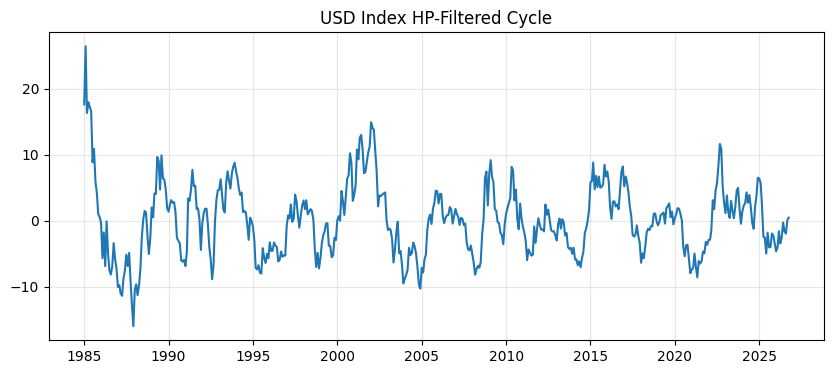

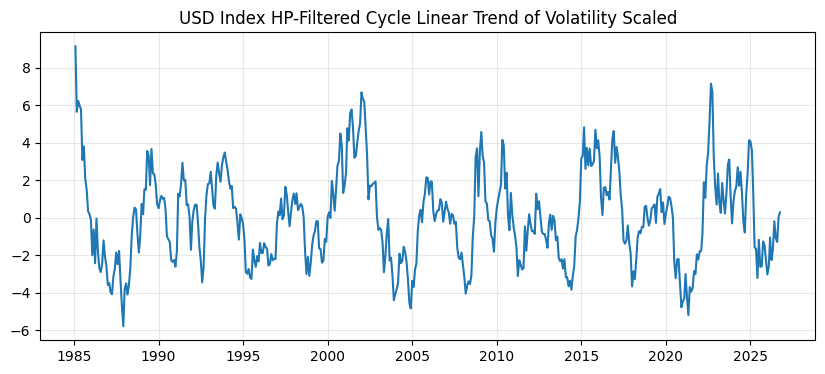

In [14]:
# -------------------------
# USD INDEX
# -------------------------
usd_ind_original = yf.download("DX-Y.NYB", start="1985-01-01", interval="1mo")["Close"]
usd_ind_original = usd_ind_original.dropna()

# -------------------------
# HP Filter 
# -------------------------
usd_ind_cycle, trend = hpfilter(usd_ind_original, lamb=129600)

usd_ind_diff = (usd_ind_cycle).diff().dropna()
usd_ind_sigma = linear_vol_scale(usd_ind_diff)

usd_ind= usd_ind_cycle/usd_ind_sigma


plt.figure(figsize=(10,4))
plt.plot(usd_ind_cycle)
plt.title("USD Index HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(usd_ind)
plt.title("USD Index HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

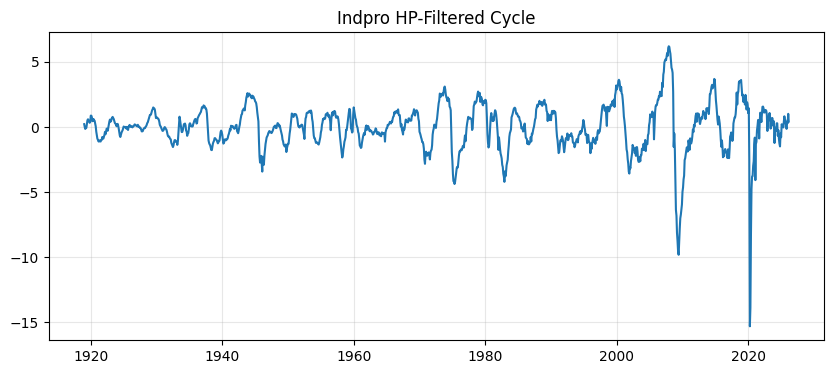

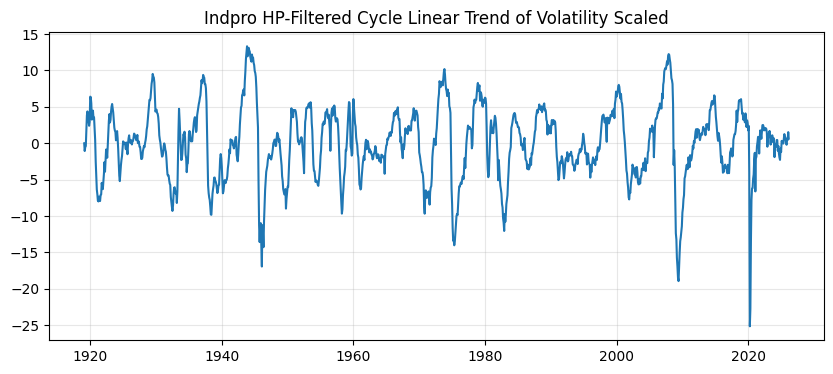

In [15]:
# -------------------------
# INDUSTRIAL PRODUCTION
# -------------------------
indpro_original = pd.read_csv("INDPRO.csv", parse_dates=["observation_date"])
indpro_original = indpro_original.dropna().set_index("observation_date")


# -------------------------
# HP Filter 
# -------------------------
indpro_cycle, trend = hpfilter(indpro_original, lamb=129600)

indpro_diff = (indpro_cycle).diff().dropna()
indpro_sigma = linear_vol_scale(indpro_diff)

indpro = indpro_cycle/indpro_sigma


plt.figure(figsize=(10,4))
plt.plot(indpro_cycle)
plt.title("Indpro HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(indpro)
plt.title("Indpro HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_74484/904516455.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  vix_original = yf.download("^VIX", start="1985-01-01", interval="1mo")["Close"]
[*********************100%***********************]  1 of 1 completed


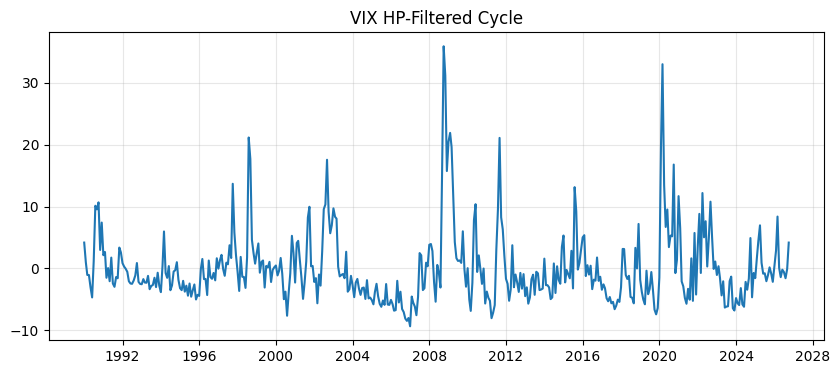

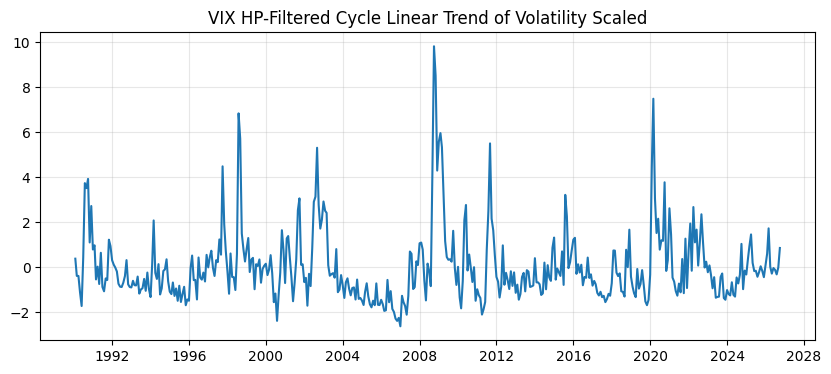

In [16]:
# -------------------------
# VIX
# -------------------------
vix_original = yf.download("^VIX", start="1985-01-01", interval="1mo")["Close"]
vix_original = vix_original.dropna()

# -------------------------
# HP Filter 
# -------------------------
vix_cycle, trend = hpfilter(vix_original, lamb=129600)

vix_diff = (vix_cycle).diff().dropna()
vix_sigma = linear_vol_scale(vix_diff)

vix= vix_cycle/vix_sigma


plt.figure(figsize=(10,4))
plt.plot(vix_cycle)
plt.title("VIX HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(vix)
plt.title("VIX HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

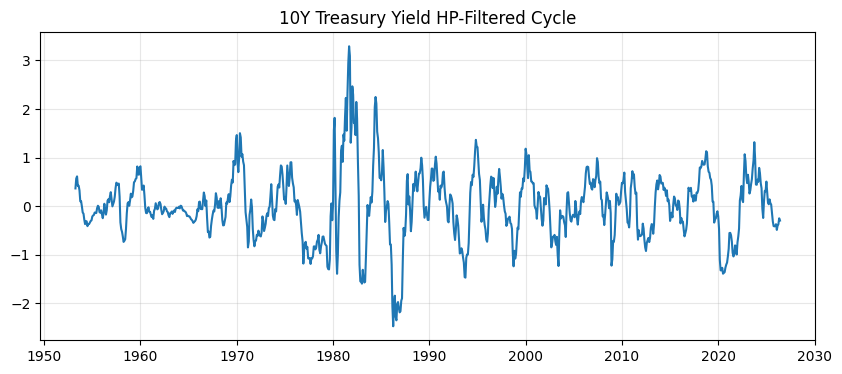

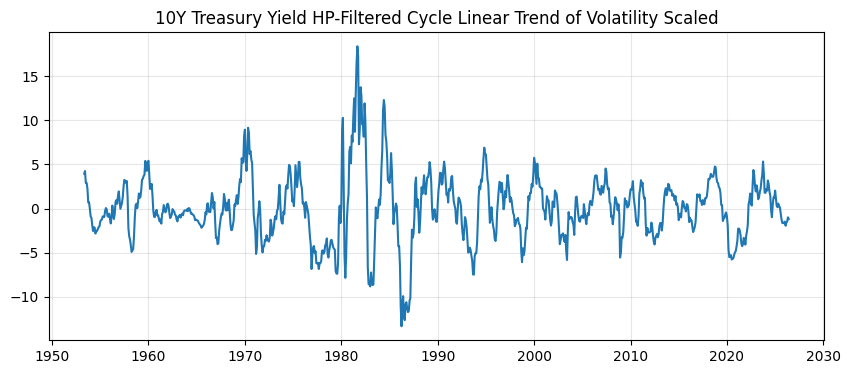

In [17]:
# -------------------------
# 10 Year Treasury Yield
# -------------------------
df_10y_treasury = pd.read_csv("GS10.csv", parse_dates=["observation_date"])
df_10y_treasury = df_10y_treasury.dropna().set_index("observation_date")


# HP filter
treasury_10y_cycle , trend = hpfilter(df_10y_treasury["GS10"], lamb=129600)

treasury_10y_diff = (treasury_10y_cycle).diff().dropna()
treasury_10y_sigma = linear_vol_scale(treasury_10y_diff)

treasury_10y= treasury_10y_cycle/treasury_10y_sigma


plt.figure(figsize=(10,4))
plt.plot(treasury_10y_cycle)
plt.title("10Y Treasury Yield HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(treasury_10y)
plt.title("10Y Treasury Yield HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

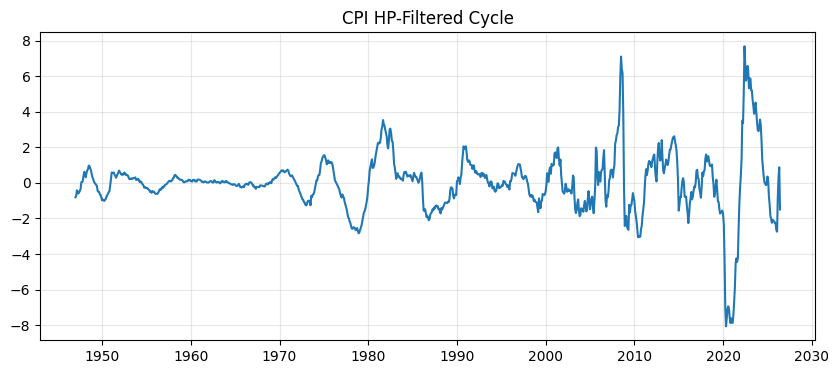

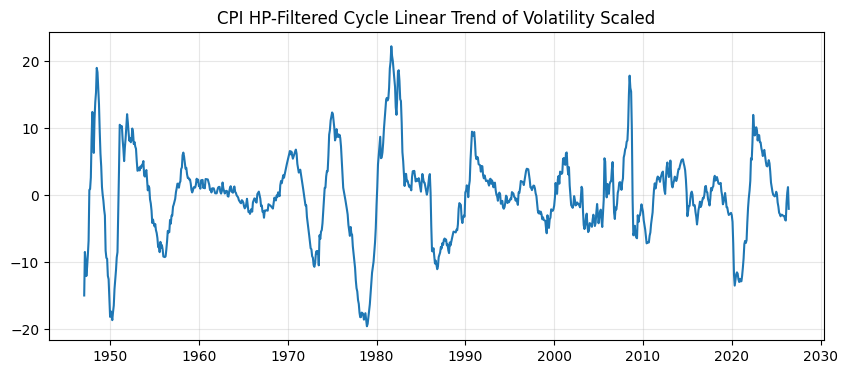

In [18]:
# -------------------------
# CPI
# -------------------------
df_cpi = pd.read_csv("CPIAUCSL.csv", parse_dates=["observation_date"])
df_cpi = df_cpi.dropna().set_index("observation_date")


# HP filter
cpi_cycle , trend = hpfilter(df_cpi["CPIAUCSL"], lamb=129600)


cpi_diff = (cpi_cycle).diff().dropna()
cpi_sigma = linear_vol_scale(cpi_diff)

cpi= cpi_cycle/cpi_sigma


plt.figure(figsize=(10,4))
plt.plot(cpi_cycle)
plt.title("CPI HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(cpi)
plt.title("CPI HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

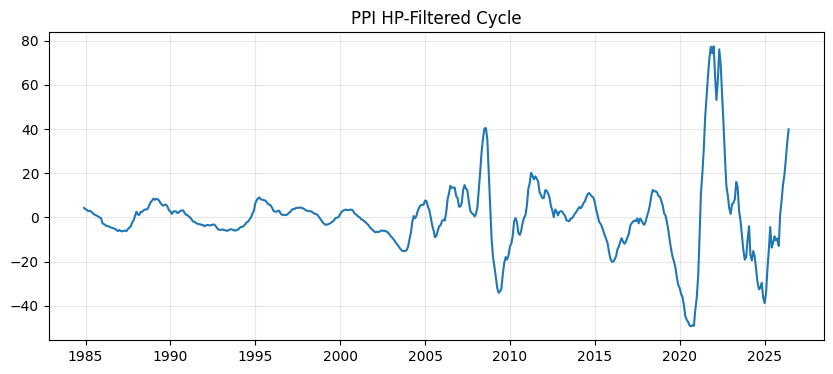

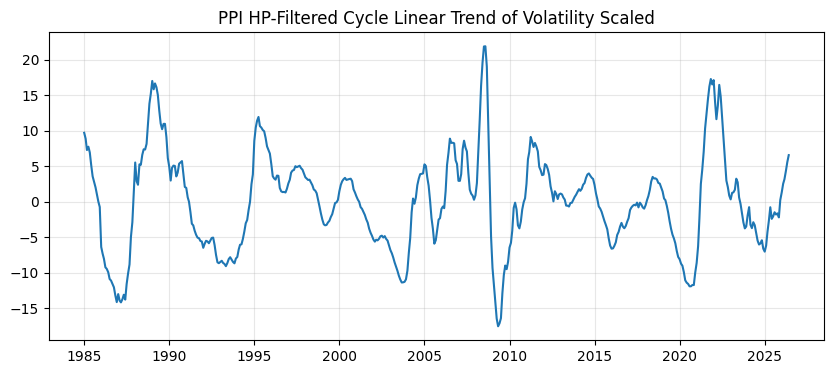

In [19]:
# -------------------------
# Producer Price Index by Industry: Primary Metal Manufacturing
# -------------------------
df_ppi = pd.read_csv("PCU331331.csv", parse_dates=["observation_date"])
df_ppi = df_ppi.dropna().set_index("observation_date")


# HP filter
ppi_cycle , trend = hpfilter(df_ppi["PCU331331"], lamb=129600)

ppi_diff = (ppi_cycle).diff().dropna()
ppi_sigma = linear_vol_scale(ppi_diff)

ppi= ppi_cycle/ppi_sigma


plt.figure(figsize=(10,4))
plt.plot(ppi_cycle)
plt.title("PPI HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(ppi)
plt.title("PPI HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_74484/389981700.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  sp500_original = yf.download("^GSPC", start="1950-01-01", interval="1mo")["Close"]
[*********************100%***********************]  1 of 1 completed


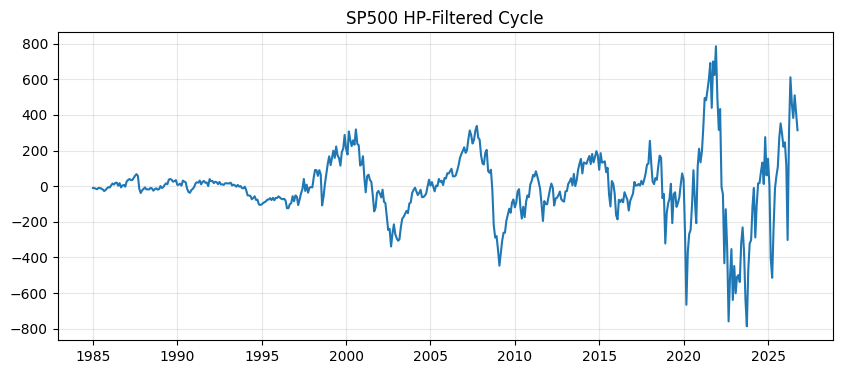

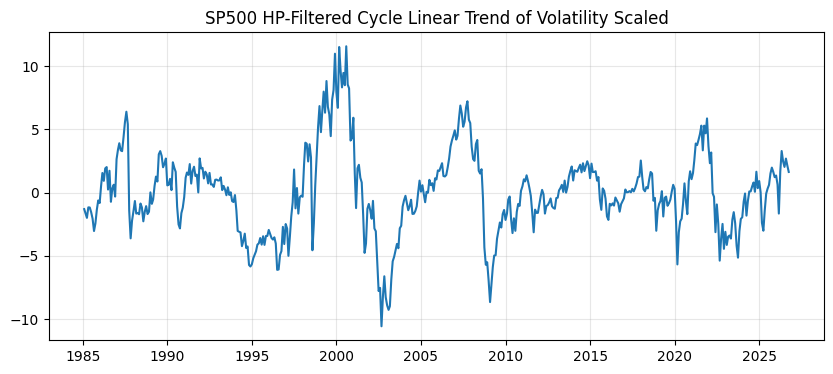

In [20]:
# -------------------------
# S&P 500
# -------------------------
sp500_original = yf.download("^GSPC", start="1950-01-01", interval="1mo")["Close"]
sp500_original = sp500_original.squeeze().dropna()

# HP filter
sp500_cycle, trend = hpfilter(sp500_original, lamb=129600)

sp500_diff = (sp500_cycle).diff().dropna()
sp500_sigma = linear_vol_scale(sp500_diff)

sp500= sp500_cycle/sp500_sigma


plt.figure(figsize=(10,4))
plt.plot(sp500_cycle)
plt.title("SP500 HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(sp500)
plt.title("SP500 HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

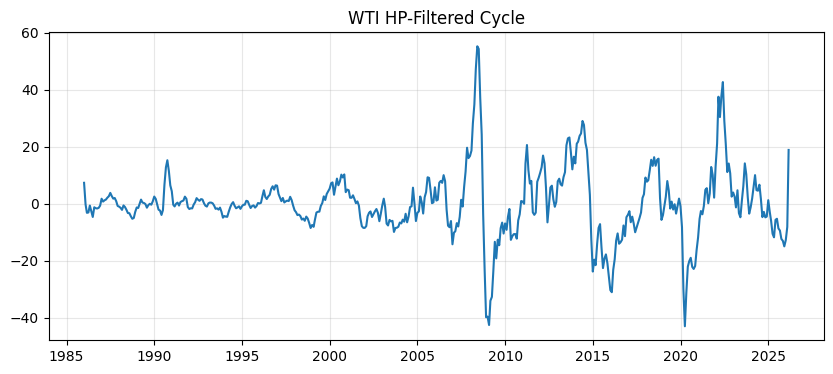

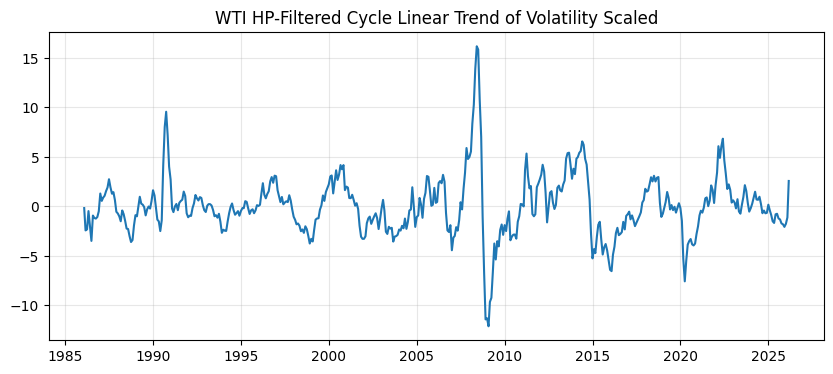

In [21]:
# -------------------------
# WTI DATA
# -------------------------
df_wti = pd.read_csv("MCOILWTICO.csv", parse_dates=["observation_date"])
df_wti = df_wti.dropna().set_index("observation_date")

# HP filter
wti_cycle, wti_trend = hpfilter(df_wti["MCOILWTICO"], lamb=129600)

wti_diff = (wti_cycle).diff().dropna()
wti_sigma = linear_vol_scale(wti_diff)

wti = wti_cycle/wti_sigma


plt.figure(figsize=(10,4))
plt.plot(wti_cycle)
plt.title("WTI HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(wti)
plt.title("WTI HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

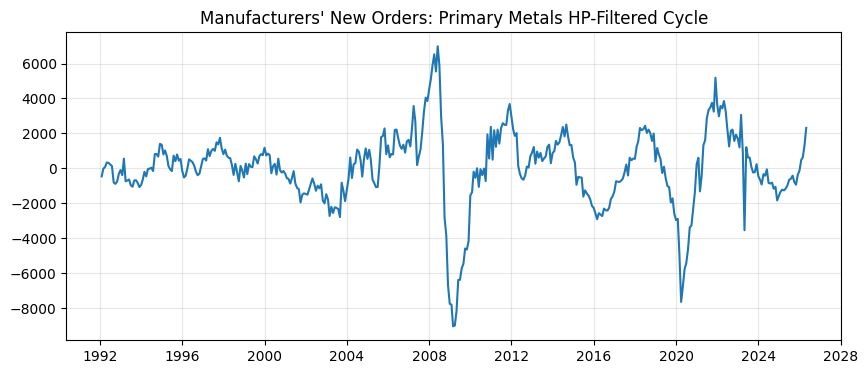

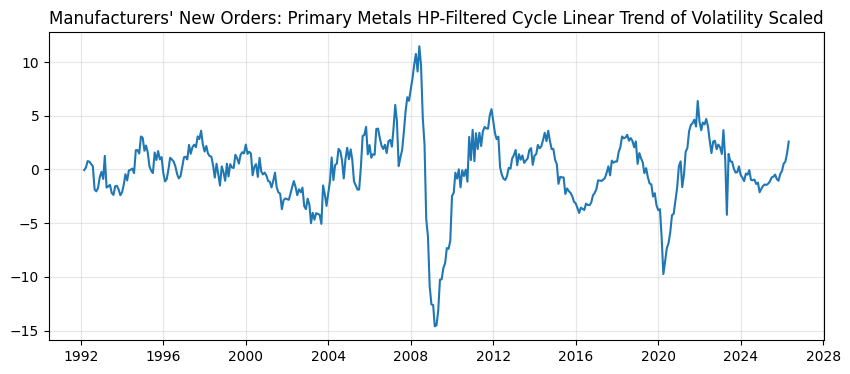

In [22]:
# -------------------------
# Manufacturers' New Orders: Primary Metals
# -------------------------
df_nom = pd.read_csv("A31SNO.csv", parse_dates=["observation_date"])
df_nom = df_nom.dropna().set_index("observation_date")


# HP filter
nom_cycle , trend = hpfilter(df_nom["A31SNO"], lamb=129600)

nom_diff = (nom_cycle).diff().dropna()
nom_sigma = linear_vol_scale(nom_diff)

nom = nom_cycle/nom_sigma


plt.figure(figsize=(10,4))
plt.plot(nom_cycle)
plt.title("Manufacturers' New Orders: Primary Metals HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(nom)
plt.title("Manufacturers' New Orders: Primary Metals HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

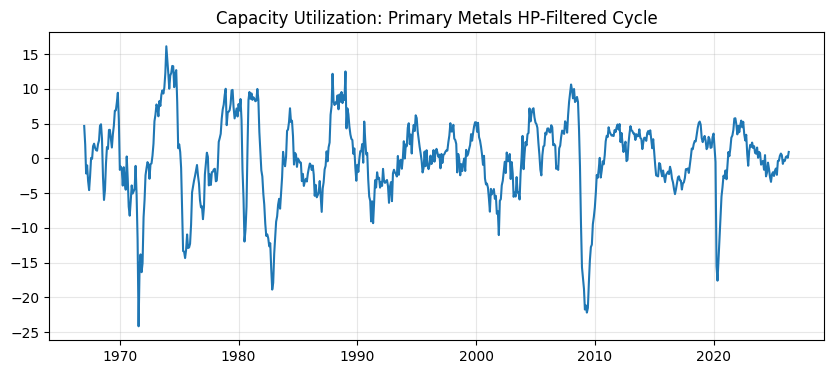

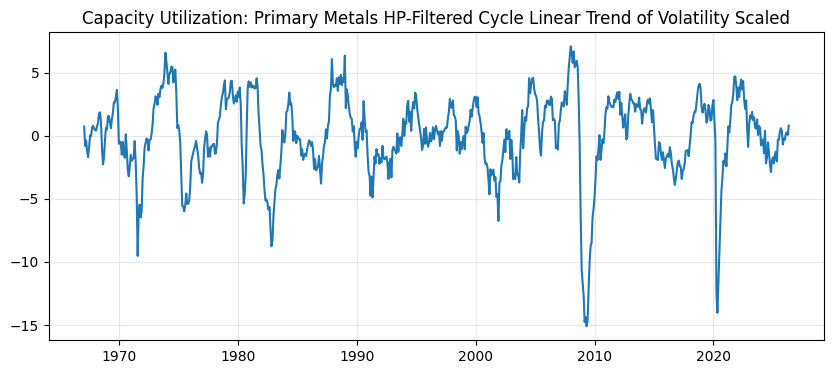

In [23]:
# -------------------------
# Capacity Utilization: Manufacturing: Durable Goods: Primary Metal
# -------------------------
df_cu = pd.read_csv("CAPUTLG331S.csv", parse_dates=["observation_date"])
df_cu = df_cu.dropna().set_index("observation_date")


# HP filter
cu_cycle , trend = hpfilter(df_cu["CAPUTLG331S"], lamb=129600)

cu_diff = (cu_cycle).diff().dropna()
cu_sigma = linear_vol_scale(cu_diff)

cu = cu_cycle/cu_sigma


plt.figure(figsize=(10,4))
plt.plot(cu_cycle)
plt.title("Capacity Utilization: Primary Metals HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(cu)
plt.title("Capacity Utilization: Primary Metals HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

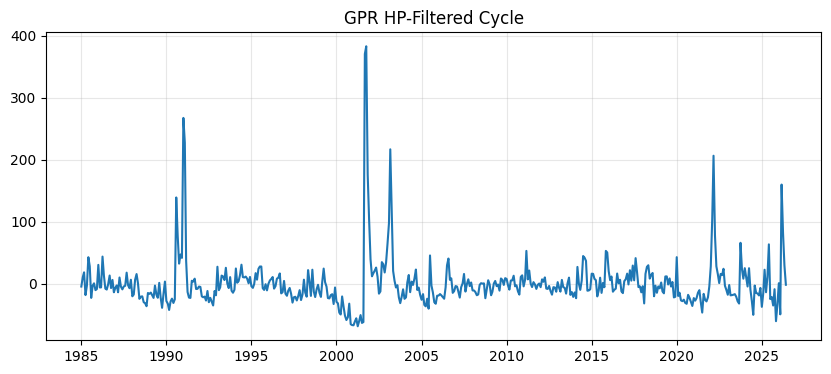

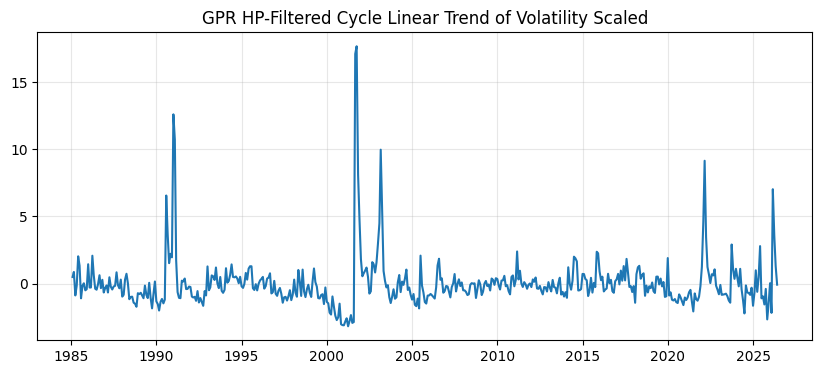

In [24]:
# -------------------------
# GPR
# -------------------------
df = pd.read_excel("GPR.xls", usecols=["month", "GPR"])

# Convert Month column to datetime
df["month"] = pd.to_datetime(df["month"])

# Set Month as index
df = df.set_index("month")

# Extract GPR series
gpr_original = df["GPR"].dropna()

# -------------------------
# HP Filter
# -------------------------
gpr_cycle, gpr_trend = hpfilter(gpr_original, lamb=129600)

gpr_diff = (gpr_cycle).diff().dropna()
gpr_sigma = linear_vol_scale(gpr_diff)

gpr = gpr_cycle/gpr_sigma


plt.figure(figsize=(10,4))
plt.plot(gpr_cycle)
plt.title("GPR HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(gpr)
plt.title("GPR HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

In [25]:
# Data and Parameters 
df = pd.concat(
    [
        df_nickel["nickel_scaled_cycle"], copper, al, usd_ind, indpro, vix, treasury_10y, cpi, ppi, sp500, wti, nom, cu, gpr
    ],
    axis=1
).dropna()

df.columns = ["nickel_scaled_cycle", "copper", "al", "usd_ind", "indpro", "vix", "treasury_10y", "cpi", "ppi", "sp500", "wti", "nom", "cu", "gpr"]
df = df.sort_index()

start_date = "1992-03-01"
end_date   = "2026-03-01"

df = df.loc[start_date:end_date].dropna()

y = df["nickel_scaled_cycle"].values
X = df[["copper", "al", "usd_ind", "indpro", "vix", "treasury_10y", "cpi", "ppi", "sp500", "wti", "nom", "cu", "gpr"]].values

var = ["copper", "al", "usd_ind", "indpro", "vix", "treasury_10y", "cpi", "ppi", "sp500", "wti", "nom", "cu", "gpr"]

print(f"Aligned sample: {len(y)} monthly observations")
print(f"Date range: {df.index.min().date()} to {df.index.max().date()}")

t0=202 # point to calculate predictive density

#Define Grid for all experiments
grid_min=-60
grid_max=60
ngrid=800
grid = np.linspace(grid_min, grid_max, ngrid)

#Define points where to calculate bimodality for all experiments
min_t = 2
max_t = len(y) 
times = np.arange(min_t, max_t)


#Parameters for effect of exogenous regressors on bimodality 
std=10
values=30

prominence = 0.01

y_limits=(-25, 40)

Aligned sample: 408 monthly observations
Date range: 1992-03-01 to 2026-03-01


----
## MAR(1,1) with Cauchy Innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma)
=
\sum_{t=2}^{T-1}
\left[
-\log(\pi\sigma)
-
\log\left(
1+\left(\frac{(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}}{\sigma}\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -653.3178257301297

Estimated parameters:
phi             =     0.6303 (0.0244)
psi             =     0.7308 (0.0321)
sigma           =     0.5148 (0.0342)

Hessian condition number:
2.720759366723973

Eigenvalues of Hessian:
[2219.76452171  895.11765102  815.86212616]

MLE diagnostics

--- MAR model diagnostics ---
Log-likelihood: -653.317826
AIC:            1312.635651
BIC:            1324.654711
R^2:            0.907455

Autocorrelation tests (standardized residuals):
  n       = 406
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 0.237654, p-value = 0.625905
    lag  5: statistic = 8.636077, p-value = 0.12449
    lag 10: statistic = 17.530236, p-value = 0.0634241
    lag 20: statistic = 30.808776, p-value = 0.0577661

Autocorrelation tests (squared standardized residuals):
  n       = 406
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 6.060349, p-value = 0.013825
    lag  5: statistic = 

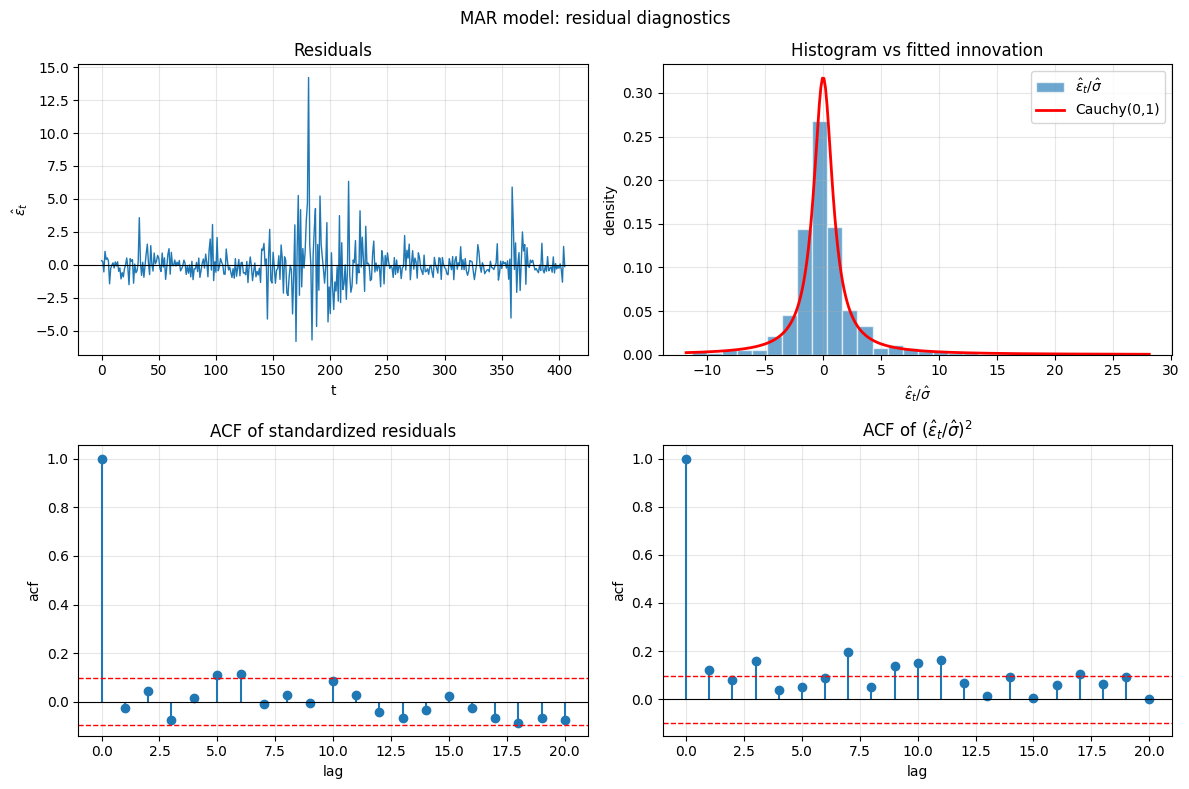

In [26]:
param_names = [ "phi", "psi", "sigma"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (1e-6, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_mar11_cauchy,
    param_names=param_names,
    bounds=bounds,
    y=y
)

params = result["params"]

### Predictive Density

$$
f(y_{T+1}\mid y_T)
=
\frac{1}{\pi \sigma}
\frac{\sigma^2}{(u_T-\psi (y_{T+1}-\phi y_T))^2+\sigma^2}
\cdot
\frac{\sigma^2+(1-|\psi|)^2 u_T^2}{\sigma^2+(1-|\psi|)^2 (y_{T+1} - \phi y_T)^2}
$$

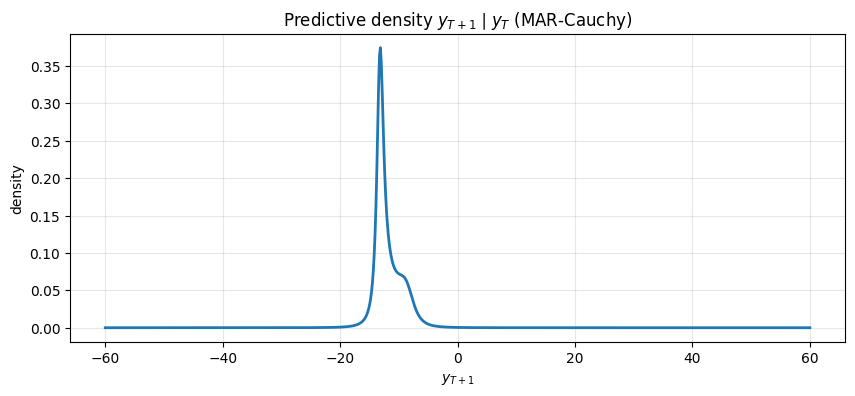

In [27]:
dens = plot_predictive_density(
    predictive_density_fn=mar_cauchy_pred_density,
    grid=grid,
    y=y,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T$ (MAR-Cauchy)"
)

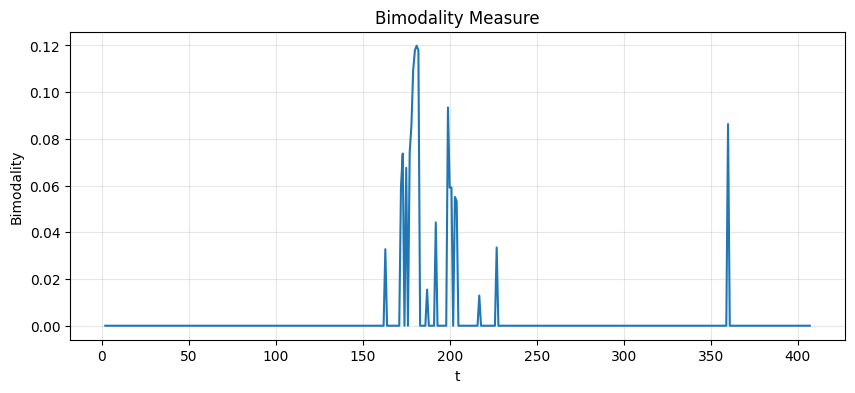

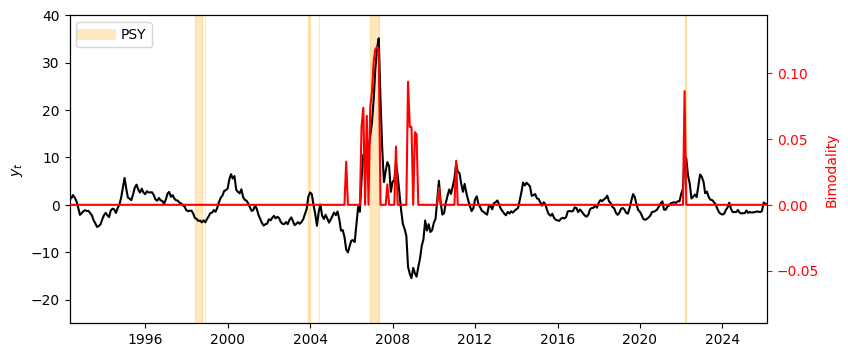

In [28]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=mar_cauchy_pred_density,
    y=y,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


----
## MARX(1,1,3) with Cauchy Innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma)
=
\sum_{t=2}^{T-1}
\left[
-\log(\pi\sigma)
-
\log\left(
1+\left(\frac{(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t}{\sigma}\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -605.9884250508587

Estimated parameters:
phi             =     0.5157 (0.0218)
psi             =     0.6755 (0.0220)
beta_copper     =     0.0961 (0.0196)
beta_al         =     0.0998 (0.0317)
beta_usd_ind    =    -0.0104 (0.0202)
beta_indpro     =     0.0175 (0.0207)
beta_vix        =     0.0020 (0.0259)
beta_treasury_10y =    -0.0162 (0.0166)
beta_cpi        =     0.0455 (0.0158)
beta_ppi        =    -0.0446 (0.0100)
beta_sp500      =    -0.0035 (0.0172)
beta_wti        =    -0.0424 (0.0235)
beta_nom        =    -0.0240 (0.0312)
beta_cu         =     0.0606 (0.0272)
beta_gpr        =    -0.0256 (0.0140)
sigma           =     0.4436 (0.0305)

Hessian condition number:
142.33057692870676

Eigenvalues of Hessian:
[81671.93427456 18739.67487149 16152.30685716  8949.95571581
  6407.60826013  5129.52914722  4620.72976226  3625.34761526
  2912.26463553  2238.94596248  1851.82997459   573.81861324
   644.98410421  1542.6890479   1129.47893764  1076

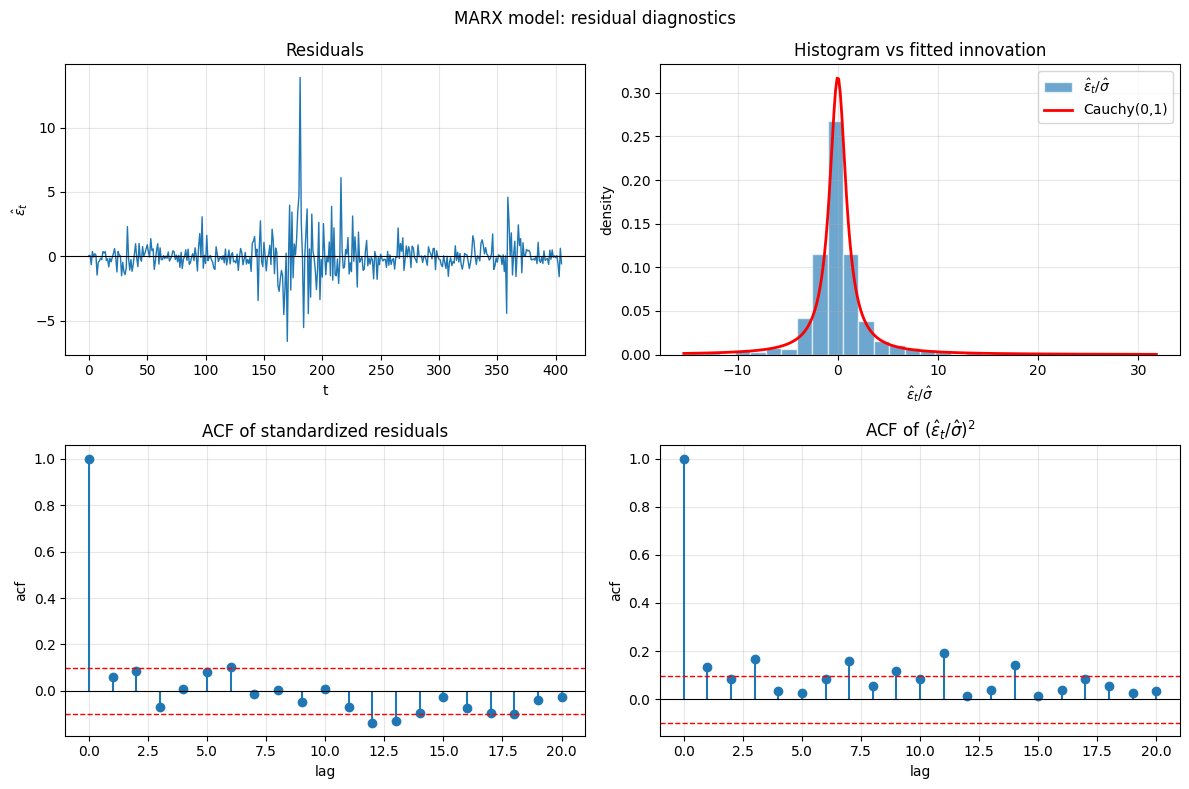

In [29]:
# MARX Cauchy MLE

param_names = [ "phi", "psi", "beta_copper", "beta_al", "beta_usd_ind", "beta_indpro", "beta_vix", "beta_treasury_10y", "beta_cpi", "beta_ppi", "beta_sp500", "beta_wti", "beta_nom", "beta_cu", "beta_gpr", "sigma"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (1e-6, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_marx_cauchy,
    param_names=param_names,
    bounds=bounds,
    y=y,
    X=X
)

params = result["params"]

### Predictive Density

$$
f(y_{T+1}\mid y_T, X_T)
=
\frac{1}{\pi \sigma}
\frac{\sigma^2}{(u_T-\psi (y_{T+1}-\phi y_T)- \beta X_T)^2+\sigma^2}
\cdot
\frac{\sigma^2+(1-|\psi|)^2 u_T^2}{\sigma^2+(1-|\psi|)^2 (y_{T+1} - \phi y_T)^2}
$$

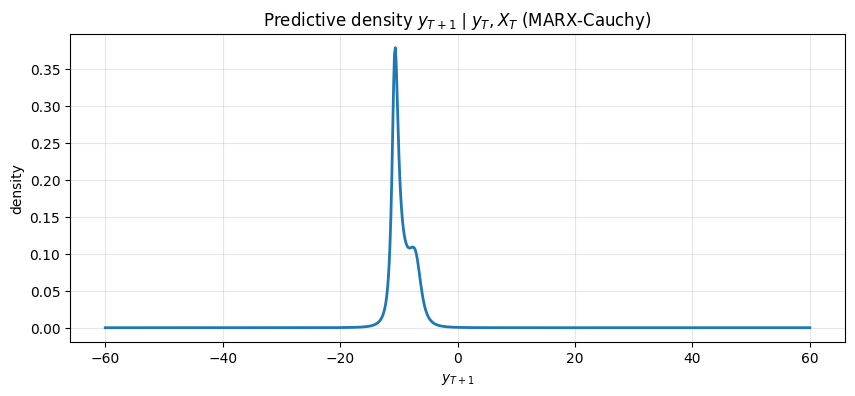

In [30]:
dens = plot_predictive_density(
    predictive_density_fn=marx_cauchy_pred_density,
    grid=grid,
    y=y,
    X=X,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T, X_T$ (MARX-Cauchy)")

### Bimodality

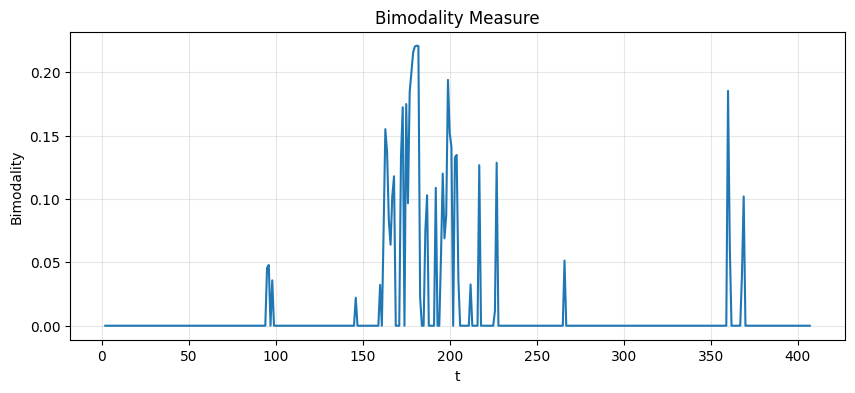

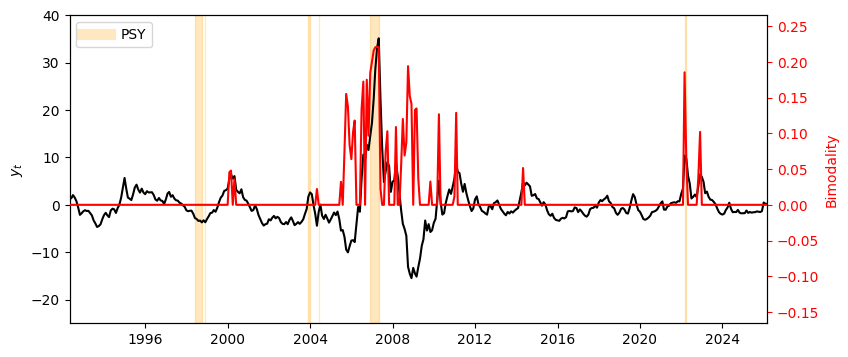

'for t, b in zip(times, bimodality_series):\n    if b > 0:\n        print(t)'

In [31]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=marx_cauchy_pred_density,
    y=y,
    X=X,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)

"""for t, b in zip(times, bimodality_series):
    if b > 0:
        print(t)"""

----
## MAR(1,1) with Student-t innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -638.049086043468

Estimated parameters:
phi             =     0.6210 (0.0373)
psi             =     0.7472 (0.0375)
sigma           =     0.6703 (0.0495)
nu              =     2.0100 (0.2696)

Hessian condition number:
126.98836814727728

Eigenvalues of Hessian:
[1722.51723128  451.38288216  716.15703736   13.56437016]

MLE diagnostics

--- MAR model diagnostics ---
Log-likelihood: -638.049086
AIC:            1284.098172
BIC:            1300.123585
R^2:            0.907528

Autocorrelation tests (standardized residuals):
  n       = 406
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 0.428266, p-value = 0.512841
    lag  5: statistic = 8.638201, p-value = 0.124395
    lag 10: statistic = 17.168977, p-value = 0.0707076
    lag 20: statistic = 29.642255, p-value = 0.0758615

Autocorrelation tests (squared standardized residuals):
  n       = 406
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 

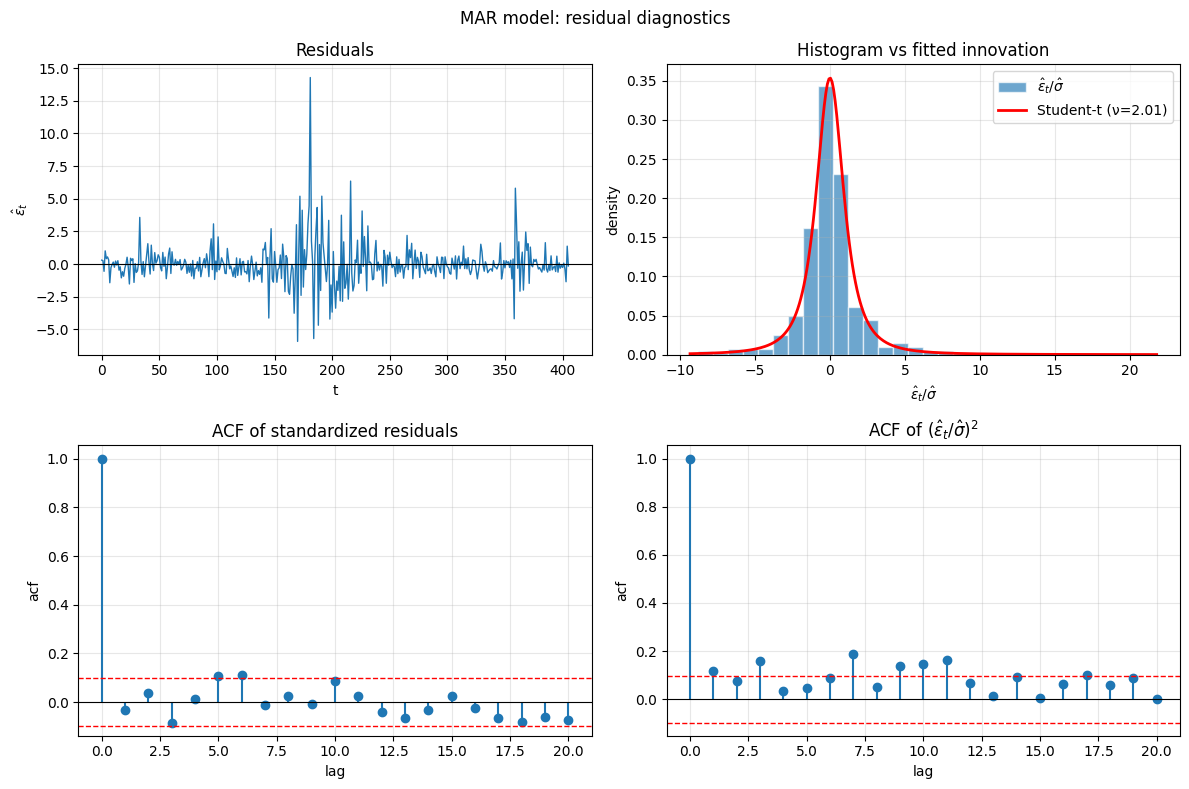

In [32]:
#MLE student-t

param_names = [ "phi", "psi", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (1e-6, None),
    (2.01, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_mar,
    param_names=param_names,
    bounds=bounds,
    y=y
)

params = result["params"]

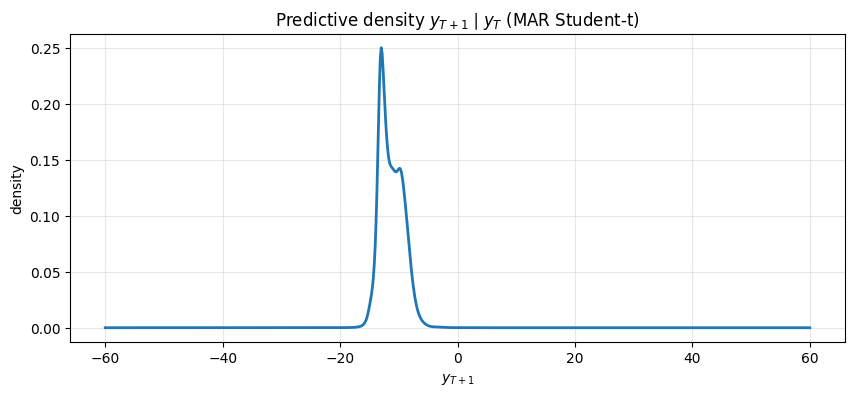

In [33]:
dens = plot_predictive_density(
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid,
    y=y,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T$ (MAR Student-t)")

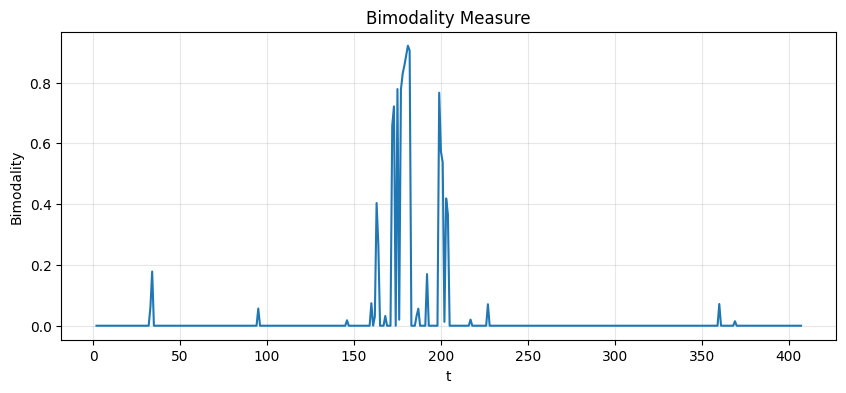

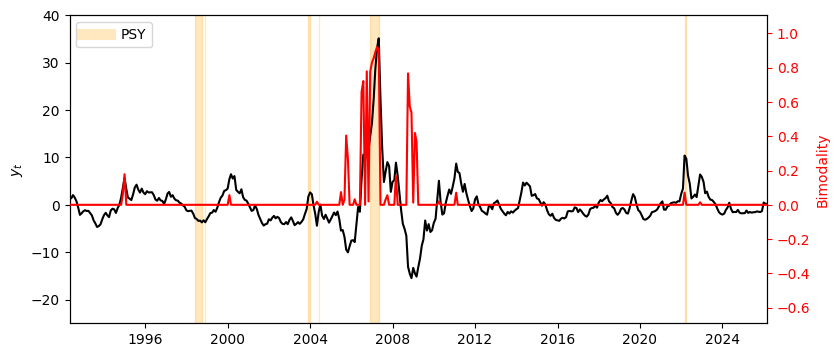

In [34]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=mar_studentt_pred_density,
    y=y,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)

----
## MARX(1,1,3) with Student-t Innovations 

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -593.8629018119417

Estimated parameters:
phi             =     0.5214 (0.0281)
psi             =     0.6763 (0.0282)
beta_copper     =     0.1038 (0.0227)
beta_al         =     0.0909 (0.0338)
beta_usd_ind    =    -0.0097 (0.0227)
beta_indpro     =     0.0141 (0.0221)
beta_vix        =     0.0073 (0.0308)
beta_treasury_10y =    -0.0138 (0.0184)
beta_cpi        =     0.0459 (0.0180)
beta_ppi        =    -0.0428 (0.0119)
beta_sp500      =     0.0037 (0.0197)
beta_wti        =    -0.0413 (0.0282)
beta_nom        =    -0.0296 (0.0366)
beta_cu         =     0.0566 (0.0318)
beta_gpr        =    -0.0227 (0.0183)
sigma           =     0.5952 (0.0472)
nu              =     2.0100 (0.2885)

Hessian condition number:
4635.669895794401

Eigenvalues of Hessian:
[5.49849062e+04 1.25924263e+04 1.08053331e+04 6.20412762e+03
 4.79258134e+03 3.55981178e+03 3.01505578e+03 2.28176566e+03
 1.18612644e+01 1.93314235e+03 1.62317627e+03 4.33362833e+02
 1.12151498e+0

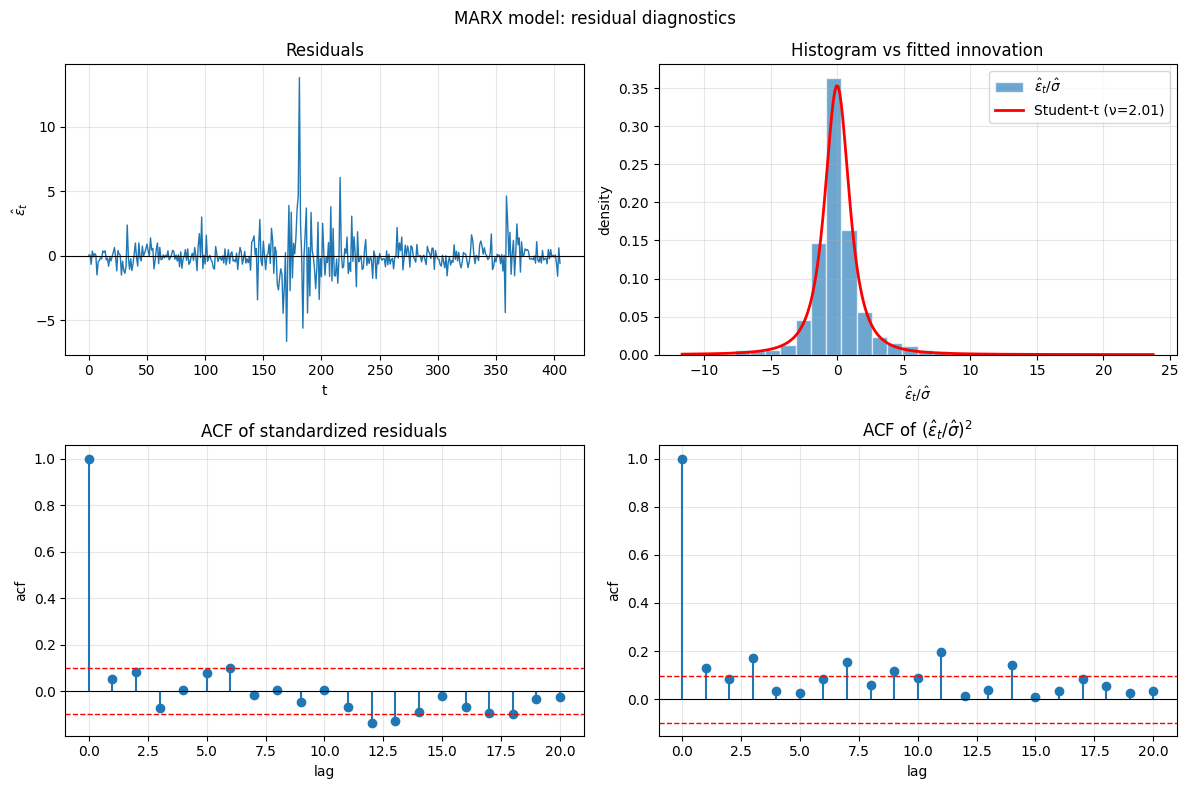

In [35]:
param_names = [ "phi", "psi", "beta_copper", "beta_al", "beta_usd_ind", "beta_indpro", "beta_vix", "beta_treasury_10y", "beta_cpi", "beta_ppi", "beta_sp500", "beta_wti", "beta_nom", "beta_cu", "beta_gpr", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (1e-6, None),
    (2.01, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_marx,
    param_names=param_names,
    bounds=bounds,
    y=y,
    X=X
)

params = result["params"]

### Sample-Based Predictive Density

$$
\hat l(u_{T+1}\mid u_T, X_T)
=
g(u_T-\psi u_{T+1} - \beta X_T)
\,
\frac{
\sum_{t=1}^{T} g(u_{T+1}-\psi u_t - \beta X_{T+1})
}{
\sum_{t=1}^{T} g(u_T-\psi u_t - \beta X_T)
}
$$

$$
g(e)
=
\frac{\Gamma\!\left(\frac{\nu+1}{2}\right)}
{\Gamma\!\left(\frac{\nu}{2}\right)\sqrt{\nu\pi}\,\sigma}
\left(
1+\frac{e^2}{\nu\sigma^2}
\right)^{-\frac{\nu+1}{2}}
$$

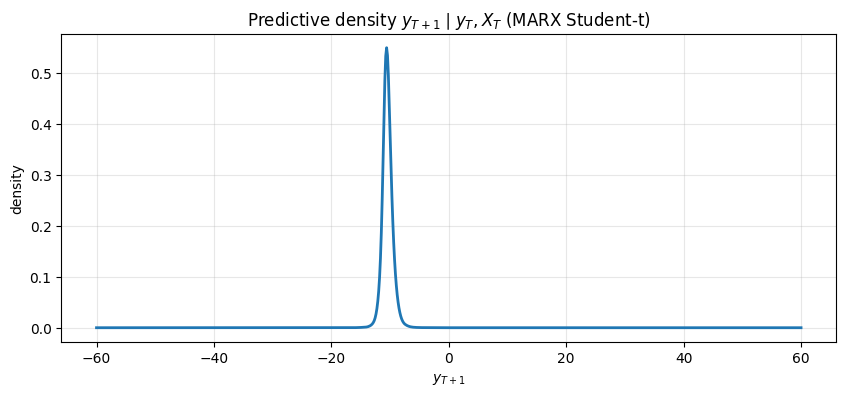

In [36]:
dens = plot_predictive_density(
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid,
    y=y,
    X=X,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T, X_T$ (MARX Student-t)")

### Bimodality

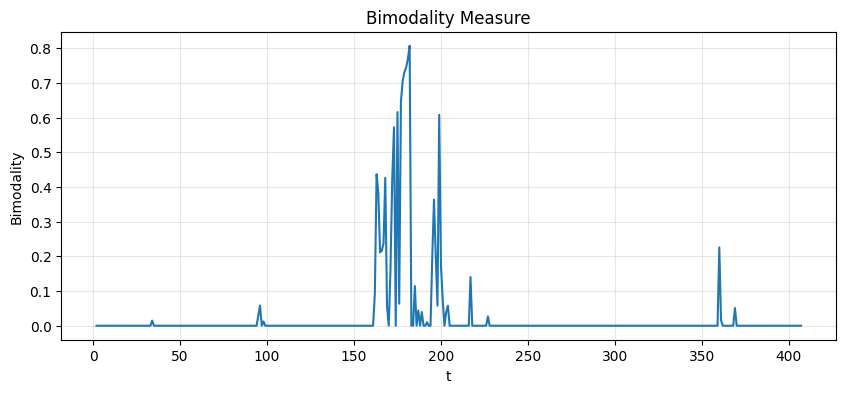

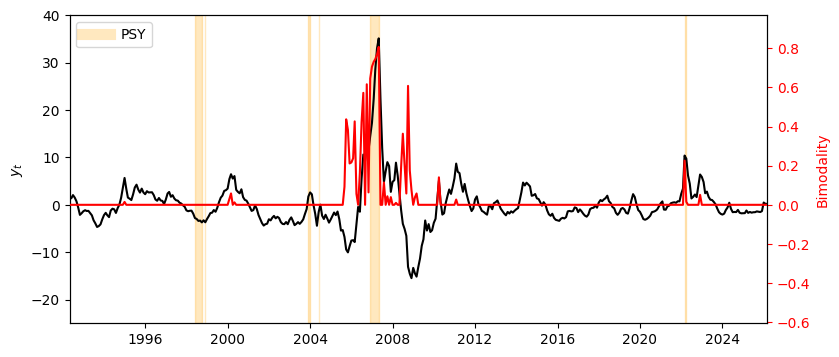

In [37]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=marx_studentt_pred_density,
    y=y,
    X=X,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)
